In [3]:
# Job Market Analytics and Salary Prediction

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load the job market dataset

df = pd.read_csv("ds_salaries.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2


In [6]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 10345
Total Columns: 19


In [7]:
print("Dataset Columns:")

for col in df.columns:
    print(col)

Dataset Columns:
job_id
job_title
company_size
company_industry
country
remote_type
experience_level
years_experience
education_level
skills_python
skills_sql
skills_ml
skills_deep_learning
skills_cloud
salary
job_posting_month
job_posting_year
hiring_urgency
job_openings


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   job_id                10345 non-null  int64 
 1   job_title             10345 non-null  object
 2   company_size          10345 non-null  object
 3   company_industry      10345 non-null  object
 4   country               10345 non-null  object
 5   remote_type           10345 non-null  object
 6   experience_level      10345 non-null  object
 7   years_experience      10345 non-null  int64 
 8   education_level       10345 non-null  object
 9   skills_python         10345 non-null  int64 
 10  skills_sql            10345 non-null  int64 
 11  skills_ml             10345 non-null  int64 
 12  skills_deep_learning  10345 non-null  int64 
 13  skills_cloud          10345 non-null  int64 
 14  salary                10345 non-null  int64 
 15  job_posting_month     10345 non-null

In [10]:
#Display all column names
df.describe()

,job_id,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.00000,10345.000000,10345.000000,10345.00000
mean,5173.000000,6.950507,0.493088,0.503045,0.507878,0.498018,0.511455,113438.22726,6.502465,2023.000387,5.00406
std,2986.488601,4.320054,0.499976,0.500015,0.499962,0.500020,0.499893,31389.20106,3.473441,1.996856,2.58382
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45083.00000,1.000000,2020.000000,1.00000
25%,2587.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89715.00000,4.000000,2021.000000,3.00000
50%,5173.000000,7.000000,0.000000,1.000000,1.000000,0.000000,1.000000,113082.00000,6.000000,2023.000000,5.00000
75%,7759.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,134894.00000,10.000000,2025.000000,7.00000
max,10345.000000,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,204143.00000,12.000000,2026.000000,9.00000


In [11]:
#Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   job_id                10345 non-null  int64 
 1   job_title             10345 non-null  object
 2   company_size          10345 non-null  object
 3   company_industry      10345 non-null  object
 4   country               10345 non-null  object
 5   remote_type           10345 non-null  object
 6   experience_level      10345 non-null  object
 7   years_experience      10345 non-null  int64 
 8   education_level       10345 non-null  object
 9   skills_python         10345 non-null  int64 
 10  skills_sql            10345 non-null  int64 
 11  skills_ml             10345 non-null  int64 
 12  skills_deep_learning  10345 non-null  int64 
 13  skills_cloud          10345 non-null  int64 
 14  salary                10345 non-null  int64 
 15  job_posting_month     10345 non-null

In [12]:
df.describe()

,job_id,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.00000,10345.000000,10345.000000,10345.00000
mean,5173.000000,6.950507,0.493088,0.503045,0.507878,0.498018,0.511455,113438.22726,6.502465,2023.000387,5.00406
std,2986.488601,4.320054,0.499976,0.500015,0.499962,0.500020,0.499893,31389.20106,3.473441,1.996856,2.58382
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45083.00000,1.000000,2020.000000,1.00000
25%,2587.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89715.00000,4.000000,2021.000000,3.00000
50%,5173.000000,7.000000,0.000000,1.000000,1.000000,0.000000,1.000000,113082.00000,6.000000,2023.000000,5.00000
75%,7759.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,134894.00000,10.000000,2025.000000,7.00000
max,10345.000000,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,204143.00000,12.000000,2026.000000,9.00000


In [13]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Total Records:", df.shape[0] * df.shape[1])

Rows: 10345
Columns: 19
Total Records: 196555


In [14]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
job_id                  0
job_title               0
company_size            0
company_industry        0
country                 0
remote_type             0
experience_level        0
years_experience        0
education_level         0
skills_python           0
skills_sql              0
skills_ml               0
skills_deep_learning    0
skills_cloud            0
salary                  0
job_posting_month       0
job_posting_year        0
hiring_urgency          0
job_openings            0
dtype: int64


In [15]:
# Check duplicate records

duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [16]:
# Remove duplicate records

df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Remaining Records:", df.shape[0])

Duplicate records removed successfully!
Remaining Records: 10345


In [17]:
# Verify missing values

print(df.isnull().sum())

job_id                  0
job_title               0
company_size            0
company_industry        0
country                 0
remote_type             0
experience_level        0
years_experience        0
education_level         0
skills_python           0
skills_sql              0
skills_ml               0
skills_deep_learning    0
skills_cloud            0
salary                  0
job_posting_month       0
job_posting_year        0
hiring_urgency          0
job_openings            0
dtype: int64


In [18]:
print("Final Dataset Rows:", df.shape[0])
print("Final Dataset Columns:", df.shape[1])

Final Dataset Rows: 10345
Final Dataset Columns: 19


In [19]:
# Count the number of job postings for each job role

job_roles = df['job_title'].value_counts()

print("Top 10 Most Demanded Job Roles:\n")

print(job_roles.head(10))


Top 10 Most Demanded Job Roles:

job_title
Business Analyst             1773
AI Engineer                  1742
Machine Learning Engineer    1740
Data Analyst                 1711
Data Scientist               1703
Data Engineer                1676
Name: count, dtype: int64


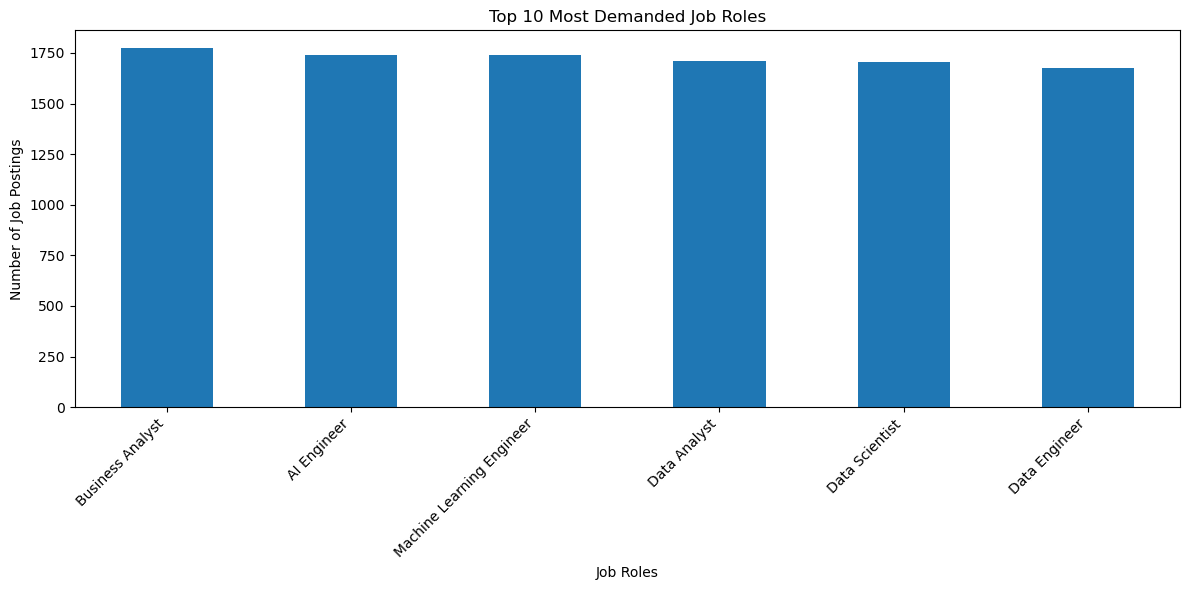

In [20]:
# Visualize Top 10 Job Roles

plt.figure(figsize=(12, 6))

job_roles.head(10).plot(kind='bar')

plt.title("Top 10 Most Demanded Job Roles")
plt.xlabel("Job Roles")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [21]:
print("Total Unique Job Roles:", df['job_title'].nunique())

print("Total Job Postings:", len(df))

Total Unique Job Roles: 6
Total Job Postings: 10345


In [23]:
# Display all column names

print(df.columns.tolist())

['job_id', 'job_title', 'company_size', 'company_industry', 'country', 'remote_type', 'experience_level', 'years_experience', 'education_level', 'skills_python', 'skills_sql', 'skills_ml', 'skills_deep_learning', 'skills_cloud', 'salary', 'job_posting_month', 'job_posting_year', 'hiring_urgency', 'job_openings']


In [24]:
df.head()

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2


In [25]:
# Salary Analysis

print("SALARY ANALYSIS")
print("--------------------------")

print("Minimum Salary:", df['salary'].min())

print("Maximum Salary:", df['salary'].max())

print("Average Salary:", round(df['salary'].mean(), 2))

print("Median Salary:", df['salary'].median())

SALARY ANALYSIS
--------------------------
Minimum Salary: 45083
Maximum Salary: 204143
Average Salary: 113438.23
Median Salary: 113082.0


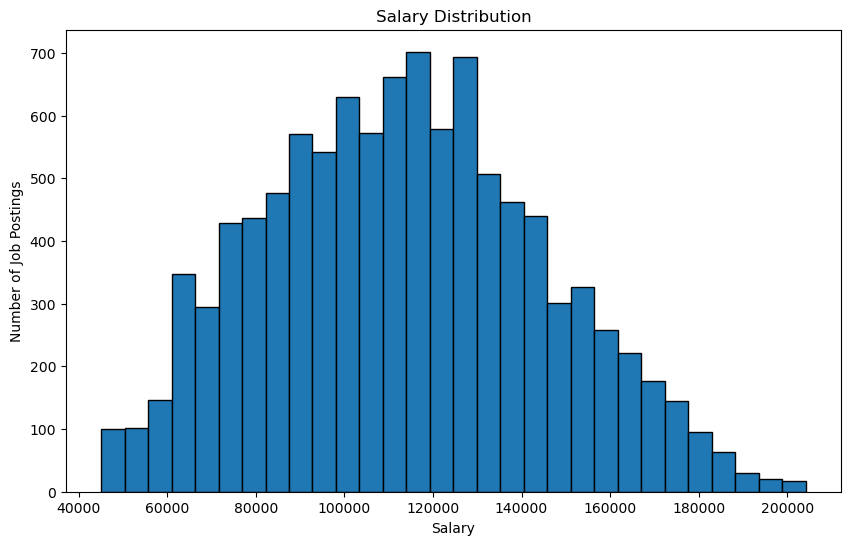

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(df['salary'], bins=30, edgecolor='black')

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Job Postings")

plt.show()

In [27]:
experience_salary = df.groupby('experience_level')['salary'].mean()

print("Average Salary by Experience Level:")
print(experience_salary)

Average Salary by Experience Level:
experience_level
Entry      89095.872758
Mid       113592.018464
Senior    138289.091520
Name: salary, dtype: float64


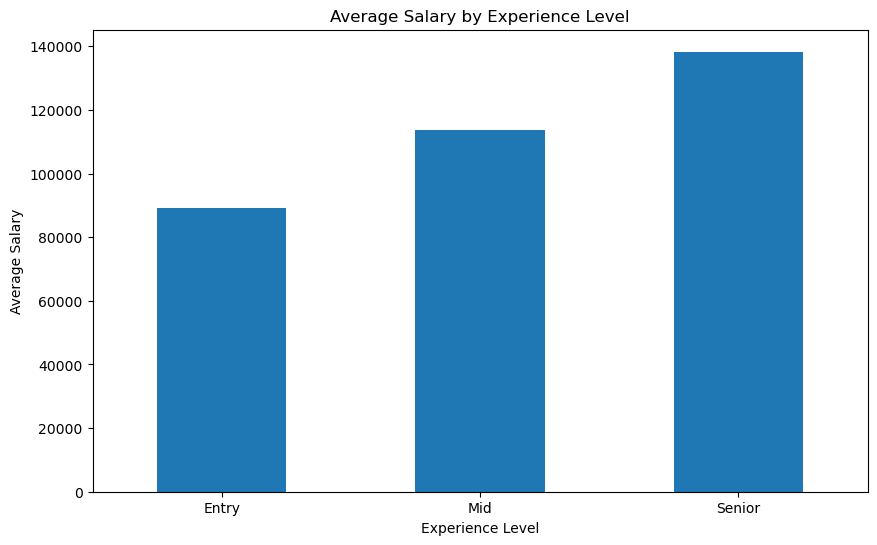

In [28]:
plt.figure(figsize=(10, 6))

experience_salary.plot(kind='bar')

plt.title("Average Salary by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary")

plt.xticks(rotation=0)

plt.show()

In [29]:
# Average Salary by Country

country_salary = df.groupby('country')['salary'].mean().sort_values(ascending=False)

print("Average Salary by Country:")
print(country_salary)


Average Salary by Country:
country
Canada       114782.863575
Singapore    114541.380537
Australia    114367.358763
USA          113280.956134
UK           112722.327946
India        112447.391156
Germany      111938.023364
Name: salary, dtype: float64


In [30]:
# Top 10 Countries by Average Salary

top_countries = country_salary.head(10)

print("Top 10 Highest-Paying Countries:")
print(top_countries)

Top 10 Highest-Paying Countries:
country
Canada       114782.863575
Singapore    114541.380537
Australia    114367.358763
USA          113280.956134
UK           112722.327946
India        112447.391156
Germany      111938.023364
Name: salary, dtype: float64


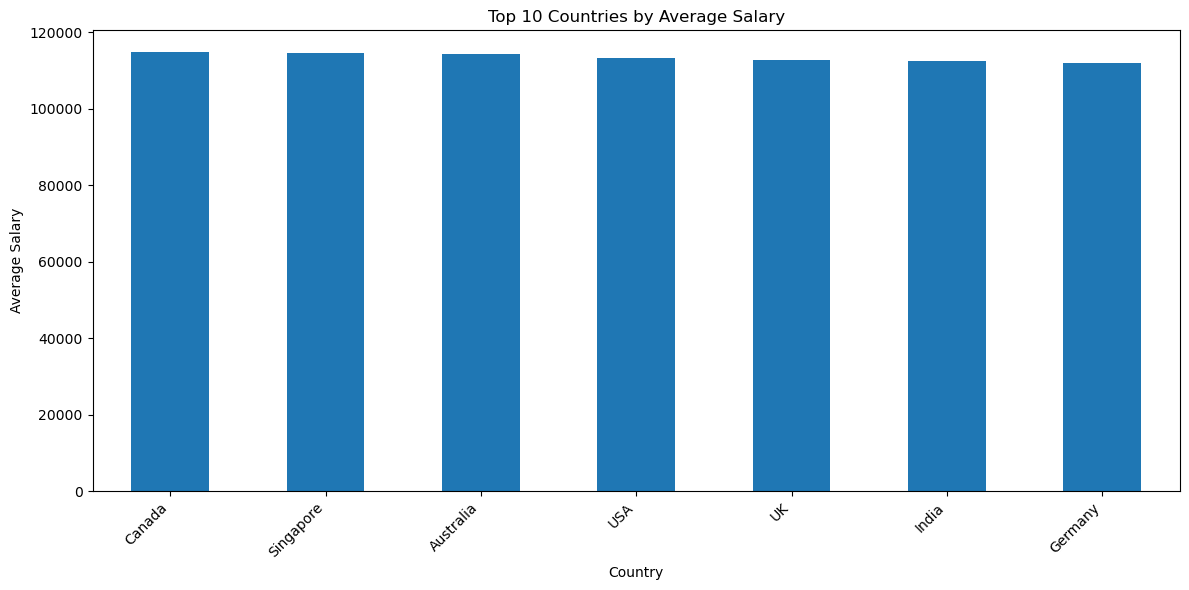

In [31]:
# Country-wise Salary Comparison

plt.figure(figsize=(12, 6))

top_countries.plot(kind='bar')

plt.title("Top 10 Countries by Average Salary")
plt.xlabel("Country")
plt.ylabel("Average Salary")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [32]:
# Number of Job Postings by Country

country_jobs = df['country'].value_counts().head(10)

print("Top 10 Countries by Job Postings:")
print(country_jobs)

Top 10 Countries by Job Postings:
country
Germany      1498
Singapore    1490
Canada       1488
UK           1485
India        1470
USA          1459
Australia    1455
Name: count, dtype: int64


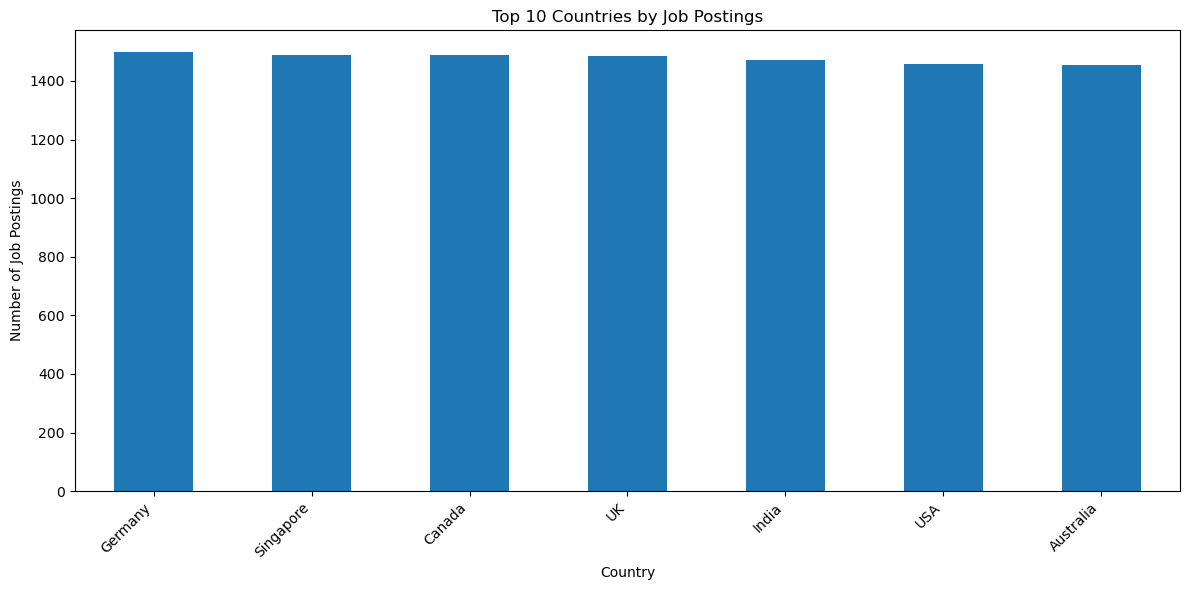

In [33]:
plt.figure(figsize=(12, 6))

country_jobs.plot(kind='bar')

plt.title("Top 10 Countries by Job Postings")
plt.xlabel("Country")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [34]:
# Most Demanded Technical Skills

skills = {
    'Python': df['skills_python'].sum(),
    'SQL': df['skills_sql'].sum(),
    'Machine Learning': df['skills_ml'].sum(),
    'Deep Learning': df['skills_deep_learning'].sum(),
    'Cloud Computing': df['skills_cloud'].sum()
}

skill_demand = pd.Series(skills).sort_values(ascending=False)

print("MOST DEMANDED TECHNICAL SKILLS")
print("--------------------------------")

print(skill_demand)

MOST DEMANDED TECHNICAL SKILLS
--------------------------------
Cloud Computing     5291
Machine Learning    5254
SQL                 5204
Deep Learning       5152
Python              5101
dtype: int64


In [35]:
# Top 5 Most Demanded Skills

top_skills = skill_demand.head(5)

print("Top 5 Demanded Skills:")
print(top_skills)

Top 5 Demanded Skills:
Cloud Computing     5291
Machine Learning    5254
SQL                 5204
Deep Learning       5152
Python              5101
dtype: int64


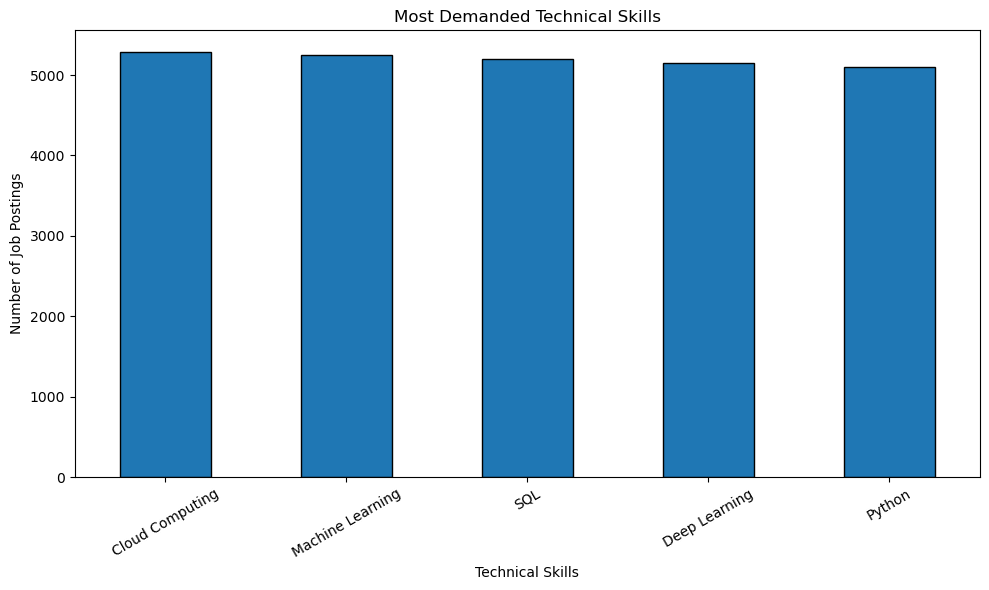

In [36]:
# Skill Demand Visualization

plt.figure(figsize=(10, 6))

skill_demand.plot(kind='bar', edgecolor='black')

plt.title("Most Demanded Technical Skills")
plt.xlabel("Technical Skills")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [37]:
# Calculate Skill Demand Percentage

skill_percentage = (skill_demand / len(df)) * 100

print("SKILL DEMAND PERCENTAGE")
print("-----------------------")

print(skill_percentage.round(2))

SKILL DEMAND PERCENTAGE
-----------------------
Cloud Computing     51.15
Machine Learning    50.79
SQL                 50.30
Deep Learning       49.80
Python              49.31
dtype: float64


In [38]:
# Average Salary Based on Years of Experience

experience_analysis = df.groupby('years_experience')['salary'].mean()

print("Average Salary by Years of Experience:")
print(experience_analysis)

Average Salary by Years of Experience:
years_experience
0     114282.148305
1     113436.471616
2     113673.095035
3     114742.500747
4     113154.974398
5     113838.097784
6     112269.121457
7     114778.481645
8     114243.895476
9     112893.534610
10    111090.147989
11    115386.104135
12    114179.672464
13    111603.990950
14    112183.957204
Name: salary, dtype: float64


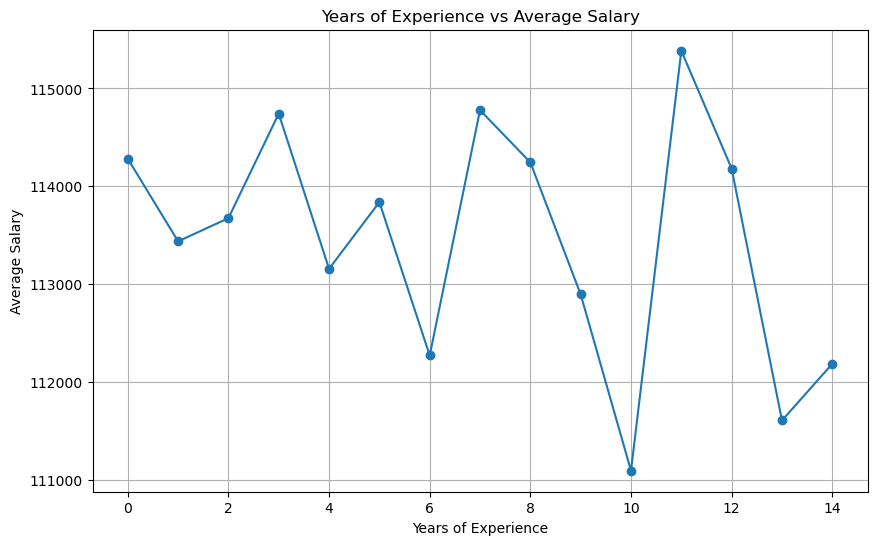

In [39]:
# Experience vs Salary Graph

plt.figure(figsize=(10, 6))

experience_analysis.plot(kind='line', marker='o')

plt.title("Years of Experience vs Average Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Average Salary")

plt.grid(True)

plt.show()

In [40]:
# Count Employees by Experience Level

experience_count = df['experience_level'].value_counts()

print("Employees by Experience Level:")
print(experience_count)

Employees by Experience Level:
experience_level
Entry     3513
Senior    3420
Mid       3412
Name: count, dtype: int64


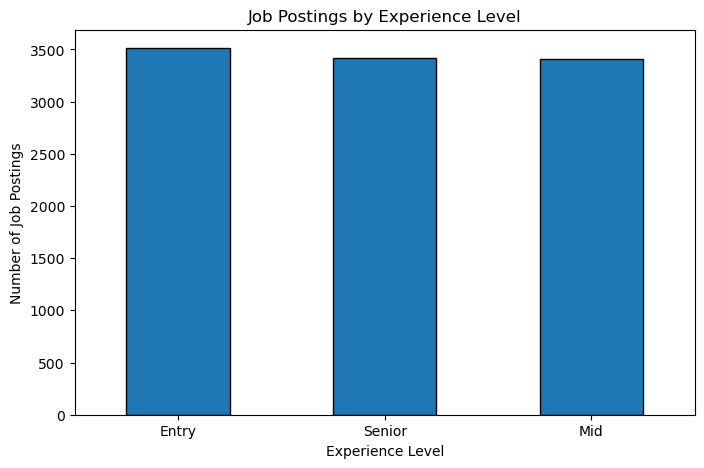

In [41]:
plt.figure(figsize=(8, 5))

experience_count.plot(kind='bar', edgecolor='black')

plt.title("Job Postings by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=0)

plt.show()

In [42]:
# Compare minimum and maximum experience salaries

min_exp = df['years_experience'].min()
max_exp = df['years_experience'].max()

min_salary = df[df['years_experience'] == min_exp]['salary'].mean()
max_salary = df[df['years_experience'] == max_exp]['salary'].mean()

print("Minimum Experience:", min_exp)
print("Average Salary:", round(min_salary, 2))

print("Maximum Experience:", max_exp)
print("Average Salary:", round(max_salary, 2))

Minimum Experience: 0
Average Salary: 114282.15
Maximum Experience: 14
Average Salary: 112183.96


In [43]:
# Import Machine Learning Libraries

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [44]:
# Prepare Input and Output

X = df[['years_experience']]
y = df['salary']

print("Input Data:")
display(X.head())

print("Output Data:")
display(y.head())

Input Data:


,years_experience
0,2
1,0
2,14
3,9
4,5


Output Data:


0    158322
1    163666
2    158556
3     95775
4    111873
Name: salary, dtype: int64

In [45]:
# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 8276
Testing Records: 2069


In [46]:
# Train Linear Regression Model

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [47]:
# Predict Salary

y_pred = lr_model.predict(X_test)

print("Actual Salaries:")
print(y_test.head(10).values)

print("\nPredicted Salaries:")
print(y_pred[:10])

Actual Salaries:
[104470  84465  56793  87146 111024 126514 112340 101846  73847 107834]

Predicted Salaries:
[113645.03579545 113836.05564687 113708.70907925 113899.72893067
 113836.05564687 114154.42206589 113326.66937642 113581.36251164
 114090.74878209 113390.34266023]


In [48]:
# Model Evaluation

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("------------------------")

print("Mean Absolute Error:", round(mae, 2))

print("Mean Squared Error:", round(mse, 2))

print("Root Mean Squared Error:", round(rmse, 2))

print("R2 Score:", round(r2, 4))

MODEL PERFORMANCE
------------------------
Mean Absolute Error: 25835.42
Mean Squared Error: 997103417.86
Root Mean Squared Error: 31576.94
R2 Score: -0.0014


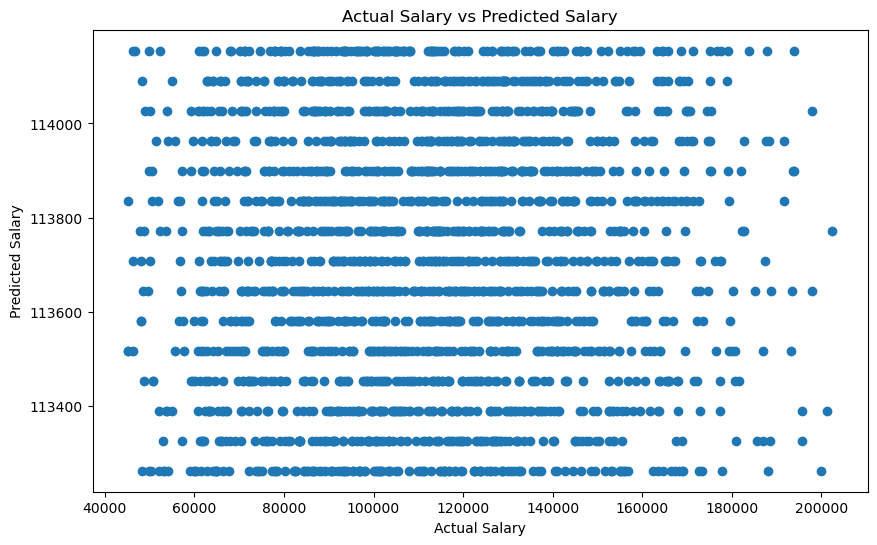

In [49]:
# Actual vs Predicted Salary

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")

plt.title("Actual Salary vs Predicted Salary")

plt.show()

In [50]:
# Predict Salary for New Employee

years = 3

predicted_salary = lr_model.predict(
    pd.DataFrame({'years_experience': [years]})
)

print("Years of Experience:", years)

print("Predicted Salary:", round(predicted_salary[0], 2))

Years of Experience: 3
Predicted Salary: 113963.4


In [51]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [52]:
# Create Random Forest Model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [53]:
# Predict salaries using Random Forest

rf_pred = rf_model.predict(X_test)

print("Actual Salaries:")
print(y_test.head(10).values)

print("\nRandom Forest Predicted Salaries:")
print(rf_pred[:10])

Actual Salaries:
[104470  84465  56793  87146 111024 126514 112340 101846  73847 107834]

Random Forest Predicted Salaries:
[115181.82750382 114005.56223624 115082.11397158 112514.5420563
 114005.56223624 114917.70718744 111901.30378276 113007.23823302
 113432.794607   114705.44993141]


In [54]:
# Evaluate Random Forest

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST MODEL PERFORMANCE")
print("--------------------------------")

print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST MODEL PERFORMANCE
--------------------------------
MAE: 25889.06
MSE: 999801281.28
RMSE: 31619.63
R2 Score: -0.0041


In [55]:
# Compare Linear Regression and Random Forest

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, rf_mae],
    'RMSE': [rmse, rf_rmse],
    'R2 Score': [r2, rf_r2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,25835.421377,31576.944403,-0.001414
1,Random Forest,25889.064012,31619.634427,-0.004124


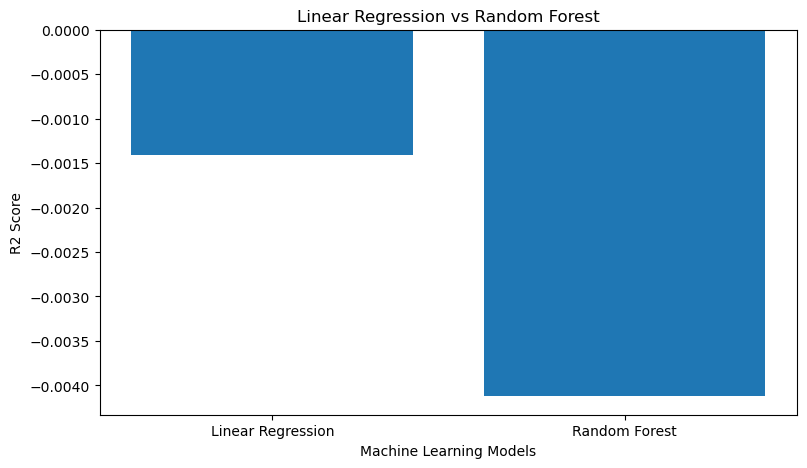

In [56]:
plt.figure(figsize=(9, 5))

plt.bar(comparison['Model'], comparison['R2 Score'])

plt.title("Linear Regression vs Random Forest")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.show()

In [57]:
# Predict salary for 3 years of experience

years = 3

new_employee = pd.DataFrame({
    'years_experience': [years]
})

predicted_salary = rf_model.predict(new_employee)

print("Years of Experience:", years)
print("Predicted Salary:", round(predicted_salary[0], 2))

Years of Experience: 3
Predicted Salary: 114210.24


In [58]:
from sklearn.tree import DecisionTreeRegressor

print("Decision Tree imported successfully!")

Decision Tree imported successfully!


In [59]:
# Create Decision Tree Model

dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=5
)

# Train the model

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [60]:
# Predict salaries using Decision Tree

dt_pred = dt_model.predict(X_test)

print("Actual Salaries:")
print(y_test.head(10).values)

print("\nDecision Tree Predicted Salaries:")
print(dt_pred[:10])

Actual Salaries:
[104470  84465  56793  87146 111024 126514 112340 101846  73847 107834]

Decision Tree Predicted Salaries:
[114344.63341804 113531.52571261 114344.63341804 113531.52571261
 113531.52571261 115033.08185053 111933.4619666  114344.63341804
 113531.52571261 114670.63734291]


In [61]:
# Evaluate Decision Tree

dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_pred)

print("DECISION TREE MODEL PERFORMANCE")
print("--------------------------------")

print("MAE:", round(dt_mae, 2))
print("MSE:", round(dt_mse, 2))
print("RMSE:", round(dt_rmse, 2))
print("R2 Score:", round(dt_r2, 4))

DECISION TREE MODEL PERFORMANCE
--------------------------------
MAE: 25884.41
MSE: 1000097311.33
RMSE: 31624.32
R2 Score: -0.0044


In [62]:
# Compare Three Machine Learning Models

comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Decision Tree'
    ],
    'MAE': [mae, rf_mae, dt_mae],
    'RMSE': [rmse, rf_rmse, dt_rmse],
    'R2 Score': [r2, rf_r2, dt_r2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,25835.421377,31576.944403,-0.001414
1,Random Forest,25889.064012,31619.634427,-0.004124
2,Decision Tree,25884.407275,31624.315191,-0.004421


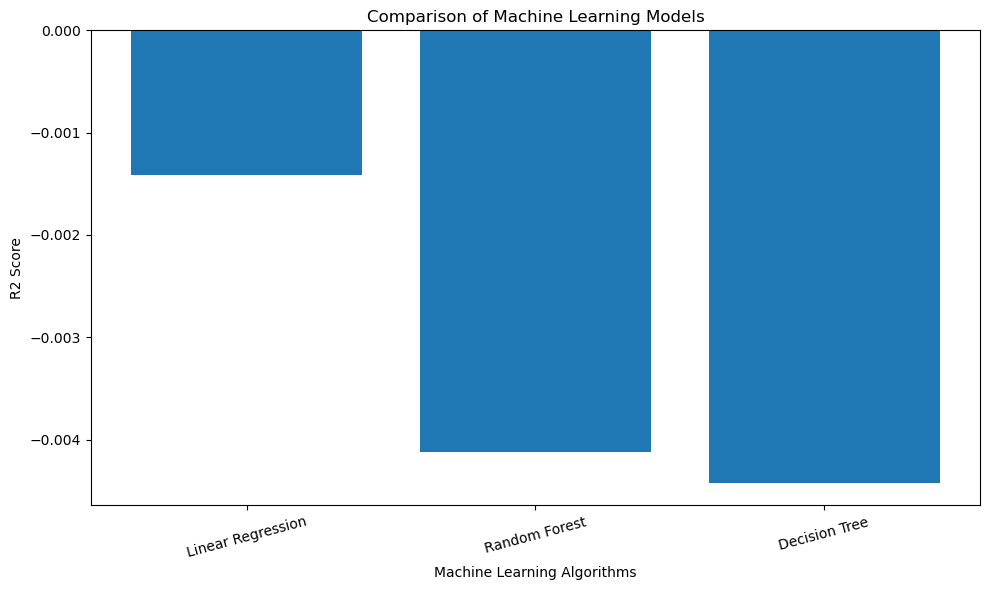

In [63]:
# Compare R2 Scores

plt.figure(figsize=(10, 6))

plt.bar(comparison['Model'], comparison['R2 Score'])

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [64]:
# Identify Best Performing Model

best_model = comparison.loc[
    comparison['R2 Score'].idxmax()
]

print("BEST MACHINE LEARNING MODEL")
print("----------------------------")

print("Model:", best_model['Model'])
print("R2 Score:", round(best_model['R2 Score'], 4))
print("MAE:", round(best_model['MAE'], 2))

BEST MACHINE LEARNING MODEL
----------------------------
Model: Linear Regression
R2 Score: -0.0014
MAE: 25835.42


In [65]:
# Select Multiple Features

features = [
    'job_title',
    'country',
    'experience_level',
    'years_experience',
    'skills_python',
    'skills_sql',
    'skills_ml',
    'skills_deep_learning',
    'skills_cloud'
]

X = df[features]

y = df['salary']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
                   job_title    country experience_level  years_experience  \
0                AI Engineer     Canada           Senior                 2   
1  Machine Learning Engineer  Australia              Mid                 0   
2  Machine Learning Engineer    Germany              Mid                14   
3           Business Analyst    Germany              Mid                 9   
4             Data Scientist    Germany              Mid                 5   

   skills_python  skills_sql  skills_ml  skills_deep_learning  skills_cloud  
0              0           0          0                     1             0  
1              1           1          1                     0             1  
2              1           0          1                     0             1  
3              0           1          0                     1             1  
4              1           1          1                     0             0  

Target Variable:
0    158322
1    163666
2    

In [66]:
# Identify Categorical and Numerical Columns

categorical_features = [
    'job_title',
    'country',
    'experience_level'
]

numerical_features = [
    'years_experience',
    'skills_python',
    'skills_sql',
    'skills_ml',
    'skills_deep_learning',
    'skills_cloud'
]

print("Categorical Features:", categorical_features)

print("\nNumerical Features:", numerical_features)

Categorical Features: ['job_title', 'country', 'experience_level']

Numerical Features: ['years_experience', 'skills_python', 'skills_sql', 'skills_ml', 'skills_deep_learning', 'skills_cloud']


In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Process categorical and numerical features

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),

        ('num', SimpleImputer(strategy='median'),
         numerical_features)
    ]
)

print("Data preprocessing completed!")

Data preprocessing completed!


In [68]:
# Split Dataset into Training and Testing

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", len(X_train_multi))

print("Testing Records:", len(X_test_multi))

Training Records: 8276
Testing Records: 2069


In [69]:
# Create Multiple Feature Random Forest Model

multi_model = Pipeline([
    ('preprocessor', preprocessor),

    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Train Model

multi_model.fit(X_train_multi, y_train_multi)

print("Multiple Feature Model Trained Successfully!")

Multiple Feature Model Trained Successfully!


In [70]:
# Predict Salaries

multi_pred = multi_model.predict(X_test_multi)

print("Actual Salaries:")
print(y_test_multi.head(10).values)

print("\nPredicted Salaries:")
print(multi_pred[:10])

Actual Salaries:
[104470  84465  56793  87146 111024 126514 112340 101846  73847 107834]

Predicted Salaries:
[100930.88        61730.99        59869.79166667  99292.855
 120855.51       118074.35       118272.46        95344.335
  79906.42933333 111799.92      ]


In [71]:
# Model Evaluation

multi_mae = mean_absolute_error(y_test_multi, multi_pred)

multi_mse = mean_squared_error(y_test_multi, multi_pred)

multi_rmse = np.sqrt(multi_mse)

multi_r2 = r2_score(y_test_multi, multi_pred)

print("MULTIPLE FEATURE MODEL PERFORMANCE")
print("-----------------------------------")

print("MAE:", round(multi_mae, 2))

print("MSE:", round(multi_mse, 2))

print("RMSE:", round(multi_rmse, 2))

print("R2 Score:", round(multi_r2, 4))

MULTIPLE FEATURE MODEL PERFORMANCE
-----------------------------------
MAE: 8387.76
MSE: 108017099.75
RMSE: 10393.13
R2 Score: 0.8915


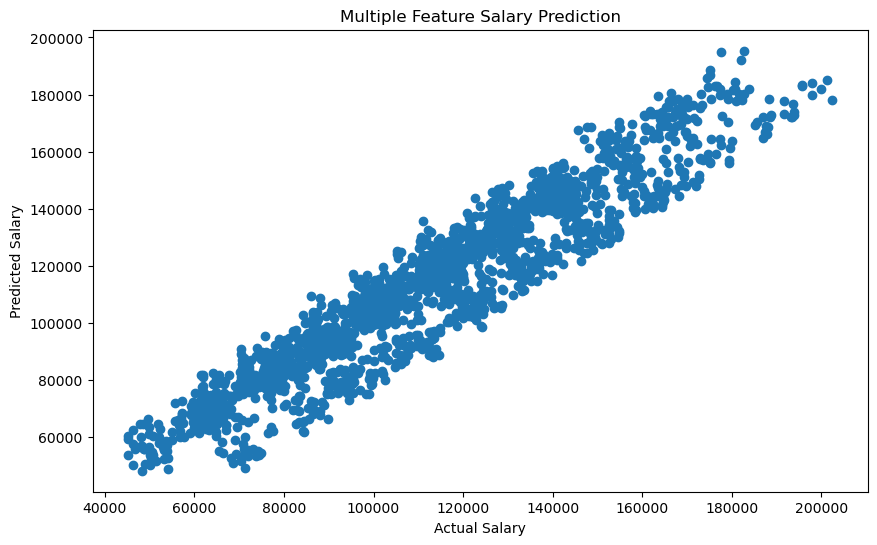

In [72]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test_multi, multi_pred)

plt.xlabel("Actual Salary")

plt.ylabel("Predicted Salary")

plt.title("Multiple Feature Salary Prediction")

plt.show()

In [73]:
# Salary Prediction System

job_role = input("Enter Job Role: ")

country = input("Enter Country: ")

experience_level = input("Enter Experience Level (EN/MI/SE/EX): ")

years_experience = float(input("Enter Years of Experience: "))

python_skill = int(input("Python Skill (1 = Yes, 0 = No): "))

sql_skill = int(input("SQL Skill (1 = Yes, 0 = No): "))

ml_skill = int(input("Machine Learning Skill (1 = Yes, 0 = No): "))

deep_learning_skill = int(input("Deep Learning Skill (1 = Yes, 0 = No): "))

cloud_skill = int(input("Cloud Computing Skill (1 = Yes, 0 = No): "))

Enter Job Role:  data analyst
Enter Country:  india
Enter Experience Level (EN/MI/SE/EX):  ml
Enter Years of Experience:  1
Python Skill (1 = Yes, 0 = No):  1
SQL Skill (1 = Yes, 0 = No):  1
Machine Learning Skill (1 = Yes, 0 = No):  1
Deep Learning Skill (1 = Yes, 0 = No):  0
Cloud Computing Skill (1 = Yes, 0 = No):  1


In [74]:
# Convert User Input into DataFrame

new_employee = pd.DataFrame({
    'job_title': [job_role],
    'country': [country],
    'experience_level': [experience_level],
    'years_experience': [years_experience],
    'skills_python': [python_skill],
    'skills_sql': [sql_skill],
    'skills_ml': [ml_skill],
    'skills_deep_learning': [deep_learning_skill],
    'skills_cloud': [cloud_skill]
})

print("Employee Details:")
display(new_employee)

Employee Details:


,job_title,country,experience_level,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud
0,data analyst,india,ml,1.0,1,1,1,0,1


In [75]:
# Predict Salary

predicted_salary = multi_model.predict(new_employee)

print("================================")
print("      SALARY PREDICTION")
print("================================")

print("Job Role:", job_role)

print("Country:", country)

print("Experience:", years_experience, "Years")

print("Predicted Salary:", round(predicted_salary[0], 2))

print("================================")

      SALARY PREDICTION
Job Role: data analyst
Country: india
Experience: 1.0 Years
Predicted Salary: 103478.57


In [76]:
import joblib

# Save trained model

joblib.dump(multi_model, "salary_prediction_model.pkl")

print("Salary Prediction Model Saved Successfully!")

Salary Prediction Model Saved Successfully!


In [77]:
# Load the saved model

loaded_model = joblib.load("salary_prediction_model.pkl")

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Dashboard libraries ready!")

Dashboard libraries ready!


In [79]:
# Project Summary

print("========================================")
print(" JOB MARKET ANALYTICS DASHBOARD")
print("========================================")

print("Total Job Postings:", len(df))

print("Total Job Roles:", df['job_title'].nunique())

print("Total Countries:", df['country'].nunique())

print("Average Salary:", round(df['salary'].mean(), 2))

print("Highest Salary:", df['salary'].max())

print("Lowest Salary:", df['salary'].min())

print("========================================")

 JOB MARKET ANALYTICS DASHBOARD
Total Job Postings: 10345
Total Job Roles: 6
Total Countries: 7
Average Salary: 113438.23
Highest Salary: 204143
Lowest Salary: 45083


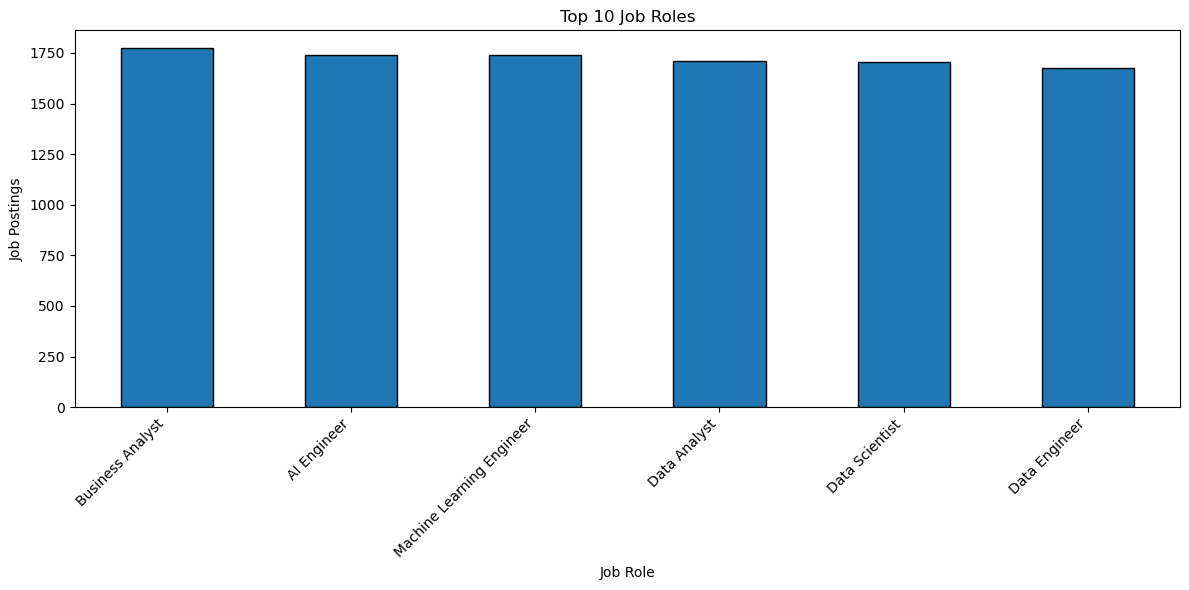

In [80]:
plt.figure(figsize=(12, 6))

df['job_title'].value_counts().head(10).plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Top 10 Job Roles")
plt.xlabel("Job Role")
plt.ylabel("Job Postings")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

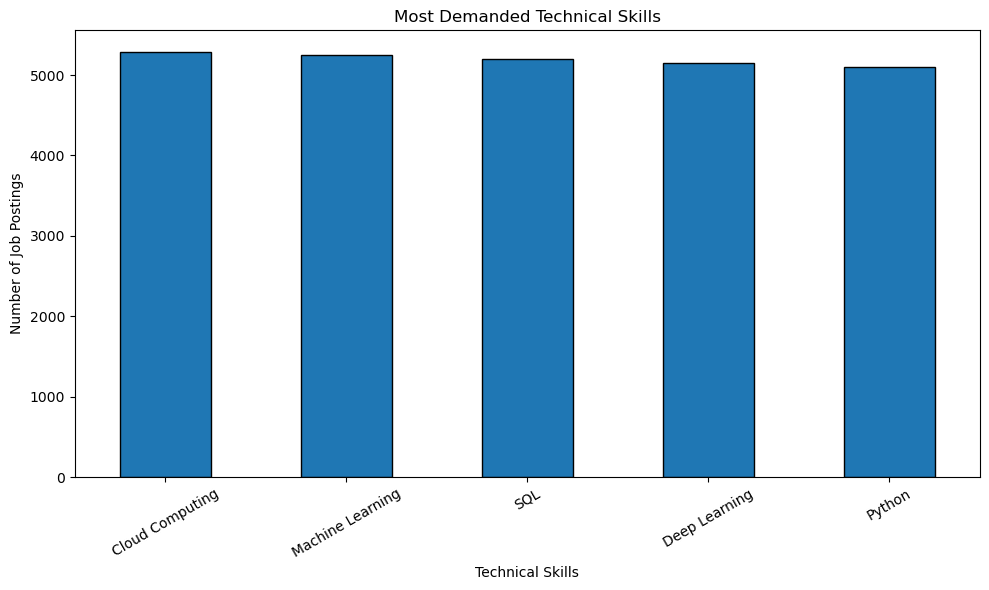

In [81]:
plt.figure(figsize=(10, 6))

skill_demand.plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Most Demanded Technical Skills")
plt.xlabel("Technical Skills")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

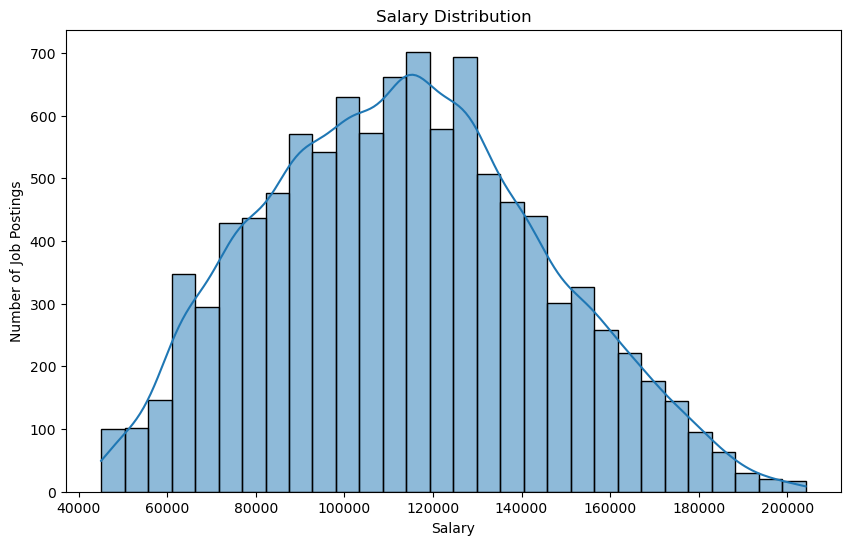

In [82]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['salary'],
    bins=30,
    kde=True
)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Job Postings")

plt.show()

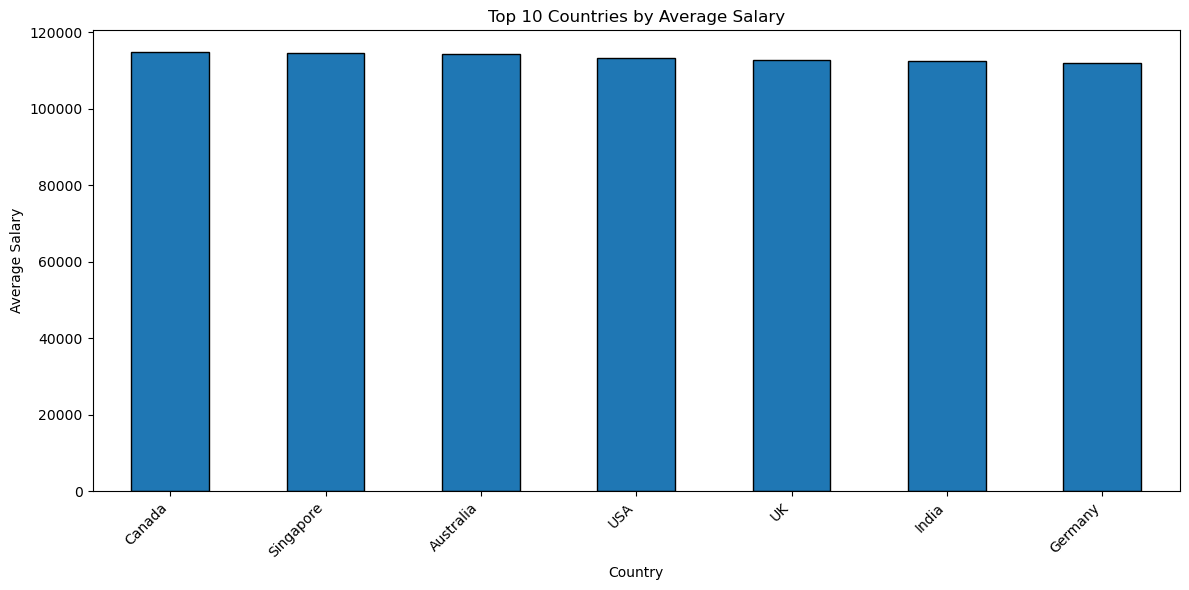

In [83]:
plt.figure(figsize=(12, 6))

country_salary.head(10).plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Top 10 Countries by Average Salary")
plt.xlabel("Country")
plt.ylabel("Average Salary")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

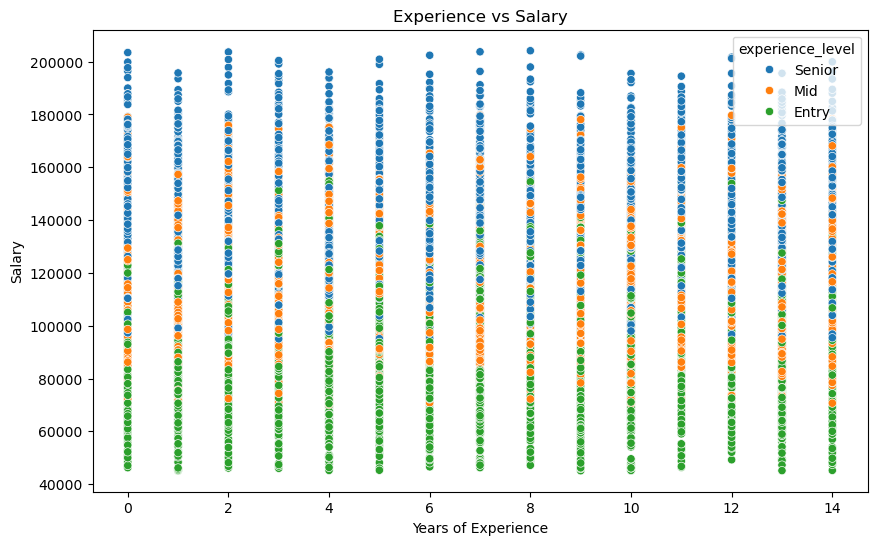

In [84]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='years_experience',
    y='salary',
    hue='experience_level'
)

plt.title("Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")

plt.show()

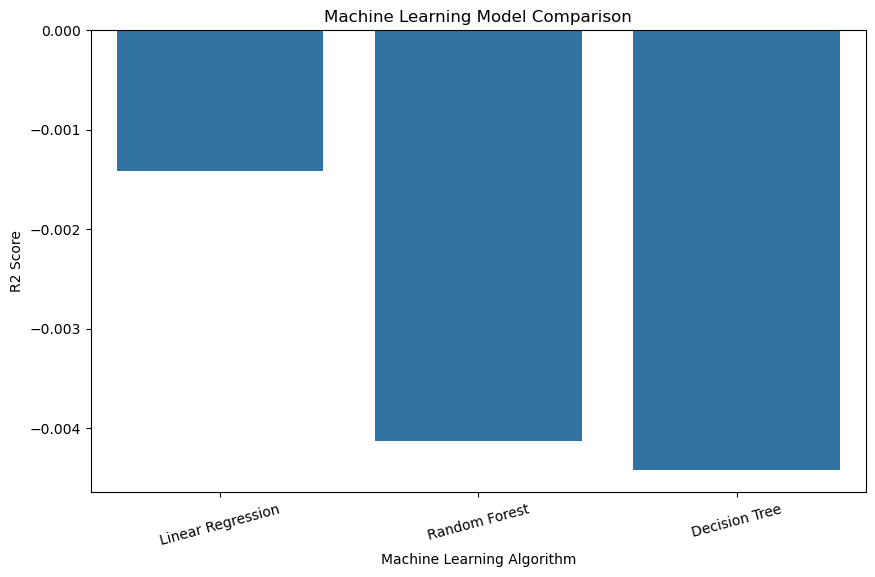

In [85]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x='Model',
    y='R2 Score'
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)
plt.show()

In [86]:
# FINAL PROJECT STATISTICS

print("==========================================")
print(" JOB MARKET ANALYTICS AND SALARY PREDICTION")
print("==========================================")

print("\n1. DATASET INFORMATION")

print("Total Job Records:", len(df))
print("Total Job Roles:", df['job_title'].nunique())
print("Total Countries:", df['country'].nunique())

print("\n2. SALARY INFORMATION")

print("Minimum Salary:", df['salary'].min())
print("Maximum Salary:", df['salary'].max())
print("Average Salary:", round(df['salary'].mean(), 2))

print("\n3. TOP 5 JOB ROLES")

print(df['job_title'].value_counts().head(5))

print("\n4. TOP 5 TECHNICAL SKILLS")

print(skill_demand.head(5))

print("\n5. BEST MACHINE LEARNING MODEL")

print(comparison.loc[comparison['R2 Score'].idxmax()])

print("\n==========================================")
print(" PROJECT ANALYSIS COMPLETED")
print("==========================================")

 JOB MARKET ANALYTICS AND SALARY PREDICTION

1. DATASET INFORMATION
Total Job Records: 10345
Total Job Roles: 6
Total Countries: 7

2. SALARY INFORMATION
Minimum Salary: 45083
Maximum Salary: 204143
Average Salary: 113438.23

3. TOP 5 JOB ROLES
job_title
Business Analyst             1773
AI Engineer                  1742
Machine Learning Engineer    1740
Data Analyst                 1711
Data Scientist               1703
Name: count, dtype: int64

4. TOP 5 TECHNICAL SKILLS
Cloud Computing     5291
Machine Learning    5254
SQL                 5204
Deep Learning       5152
Python              5101
dtype: int64

5. BEST MACHINE LEARNING MODEL
Model       Linear Regression
MAE              25835.421377
RMSE             31576.944403
R2 Score            -0.001414
Name: 0, dtype: object

 PROJECT ANALYSIS COMPLETED


In [87]:
# Save Job Market Analysis Results

final_results = pd.DataFrame({
    'Technical Skill': skill_demand.index,
    'Job Demand Count': skill_demand.values,
    'Demand Percentage': skill_percentage.values
})

final_results.to_csv("job_market_analysis_results.csv", index=False)

print("Final Analysis Results Saved Successfully!")

Final Analysis Results Saved Successfully!


In [88]:
# Save Machine Learning Model Comparison

comparison.to_csv("model_performance_results.csv", index=False)

print("Model Performance Results Saved Successfully!")

Model Performance Results Saved Successfully!


In [89]:
# Save Cleaned Dataset

df.to_csv("cleaned_job_market_dataset.csv", index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [90]:
import joblib

joblib.dump(multi_model, "final_salary_prediction_model.pkl")

print("Final Salary Prediction Model Saved Successfully!")

Final Salary Prediction Model Saved Successfully!
